# MJO: RMM skill of the initialization configurations

## Purpose

How long each initialization configuration predicts the MJO, measured with the Wheeler-Hendon RMM index.

## Inputs

Model daily FLUT (daily means) and U850/U200 (00Z states) of every member and start. Observed RMM EOFs and climatology `RMM_EOF_FILE` (built by `hind_atm_mjo/03_compute_and_plot_rmm_skill.ipynb`, also used by `fcst_atm_mjo/`); NOAA OLR and ERA5 U850/U200 for the observed index and the history before each start; the BoM index as a check.

## Method

Daily model values: FLUT daily means; U850/U200 as the mean of the 00Z states at the start and end of each day (`util.fcst_init_data.open_member_daily(pair_mean=True)`). Each member is projected on the observed EOFs (`util.mjo_rmm_projection.RmmProjector`), with the previous-120-day mean taken from the observations before the start. Skill pooled over the start dates per lead (`util.fcst_init_skill.rmm_lead_skill`): bivariate COR and RMSE of the ensemble mean (Rashid et al. 2011), ensemble spread, amplitude error; and over lead windows (`util.mjo_rmm_projection.rmm_window_skill` per start, averaged).

Caveat: 4 starts per season (8 in all) give a noisy COR per lead day; the window table pools all days of a window. The hindcasts save U850/U200 only as instantaneous 00Z states (`U850:I`, `U200:I` in the daily h1 stream; the 6-hourly h2 stream has no pressure-level winds), so the model daily mean is estimated from the two 00Z states bounding each day, while the observed index uses true ERA5 daily means (`ERA5/1x1/daily`). Computing the observed index both ways for 2012-2013 changes it negligibly (bivariate COR 0.9995, RMSE 0.03, against forecast RMSE of 0.5-1.5): the point errors (RMS 0.9 m s-1 at 850 hPa, 1.8 m s-1 at 200 hPa, 15S-15N) average out in the large-scale EOF projection. True model daily means would need `U850:A`, `U200:A` in the output of future hindcasts.

## Outputs

`data/hind_lead_eval/mjo/`: `rmm_OBS_<SEASON>.nc`, `rmm_<CONFIG>_<YYYYMMDD>.nc` (member x time), `rmm_lead_skill_<CONFIG>_<SET>.nc`, `rmm_window_skill.csv`; figures in `figure/hind_lead_eval/mjo/`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction, ELM layer thicknesses
WORKFLOW_NAME = "hind_lead_eval"

# Initialization configurations (configs/fcst_init_experiment_config.py) and seasons (4 starts each)
CONFIGS = ("CLIM_BASE", "HYB_BASE", "DA_ATM", "DA_LND", "DA_COUPLED")
SEASONS = ("DJF", "JJA")
MAX_LEAD = 56          # lead days (8 weeks)
MAX_MEMBERS = None     # e.g. 4 for a quick test
REQUIRE_ALL_MEMBERS = True  # skip a (configuration, season) until every member's stream is regenerated

RMM_EOF_FILE = DIAGNOSTIC_OUTPUT_ROOT / "data/hind_atm_mjo/rmm/rmm_obs_eof_1986-2017_climo31_rm120.nc"
BOM_RMM_FILE = OBSERVATION_ROOT / "MJO_INDEX/rmm.74toRealtime.txt"
HISTORY_DAYS = 150     # observed days before each start (>= 120)
EXAMPLE_INIT = "2011-12-31"  # start shown in the ensemble phase-space figure

FORCE_COMPUTE = False
SHOW = True
FIGURE_DPI = 200

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import MEMBERS, check_configs, init_dates, readiness
from configs.output_paths import workflow_output_dirs

check_configs(CONFIGS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, "mjo", output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(data_root=INPUT_DATA_ROOT, land_support_dir=LAND_SUPPORT_DIR)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")


def members_of(config):
    return MEMBERS[config] if MAX_MEMBERS is None else MEMBERS[config][:MAX_MEMBERS]


def save(fig, name):
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/mjo
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/mjo


## 4. Read input

In [4]:
status = readiness(CONFIGS, SEASONS, streams=(("atm", "daily"),), data_root=INPUT_DATA_ROOT)
summary = status.groupby(["config", "season"]).agg(ready=("ready", "sum"), members=("members", "sum"))
display(summary.unstack("season"))
RUNS = [(c, s) for (c, s), row in summary.iterrows() if row.ready >= (row.members if REQUIRE_ALL_MEMBERS else 1)]
print(f"[RUNS] {len(RUNS)} of {len(summary)} configuration-seasons ready: {RUNS}")

ready     members    
season       DJF JJA     DJF JJA
config                          
CLIM_BASE     80  80      80  80
DA_ATM        80  28      80  80
DA_COUPLED    80  28      80  80
DA_LND        80  28      80  80
HYB_BASE      80  80      80  80

[RUNS] 7 of 10 configuration-seasons ready: [('CLIM_BASE', 'DJF'), ('CLIM_BASE', 'JJA'), ('DA_ATM', 'DJF'), ('DA_COUPLED', 'DJF'), ('DA_LND', 'DJF'), ('HYB_BASE', 'DJF'), ('HYB_BASE', 'JJA')]


## 5. Derive and save

Observed RMM over each season (with history), then the RMM of every member of every configuration and start. Saved files are reused unless `FORCE_COMPUTE`.

In [5]:
from util.fcst_init_data import open_ensemble
from util.hind_observation_data import open_reference_daily
from util.mjo_rmm_projection import RmmProjector, read_bom_rmm

if not Path(RMM_EOF_FILE).exists():
    raise FileNotFoundError(f"{RMM_EOF_FILE} not found: build it with hind_atm_mjo/03_compute_and_plot_rmm_skill.ipynb")
proj = RmmProjector(xr.load_dataset(RMM_EOF_FILE))
bom = read_bom_rmm(BOM_RMM_FILE)
products = {"FLUT": "NOAA_OLR", "U850": "ERA5_DAILY", "U200": "ERA5_DAILY"}
day = np.timedelta64(1, "D")
obs_rmm, fcst_rmm, obs_fields = {}, {}, {}
for season in SEASONS:
    inits = init_dates([season])[season]
    start, end = str(min(inits) - HISTORY_DAYS * day), str(max(inits) + (MAX_LEAD + 2) * day)
    obs_fields[season] = {v: open_reference_daily(p, v, start=start, end=end, lat_range=(-20.0, 20.0),
                                                  observation_root=OBSERVATION_ROOT).load()
                          for v, p in products.items()}
    obs_rmm[season] = proj.project(obs_fields[season], "OBS")
    obs_rmm[season].to_netcdf(data_dir / f"rmm_OBS_{season}.nc")
    for c in CONFIGS:
        if (c, season) not in RUNS:
            continue
        for init in inits:
            out = data_dir / f"rmm_{c}_{str(init).replace('-', '')}.nc"
            if out.exists() and not FORCE_COMPUTE:
                fcst_rmm[c, init] = xr.load_dataset(out)
                continue
            fields = {v: open_ensemble(c, init, v, members=members_of(c), max_lead=MAX_LEAD, pair_mean=True, **ROOTS)
                      .swap_dims(lead="time").drop_vars("lead").sel(lat=slice(-20, 20)).load()
                      for v in ("FLUT", "U850", "U200")}
            members = {k + 1: {v: f.isel(member=k, drop=True).dropna("time", how="all") for v, f in fields.items()}
                       for k in range(fields["FLUT"].sizes["member"])}
            history = {v: f.sel(time=slice(None, init - day)) for v, f in obs_fields[season].items()}
            fcst_rmm[c, init] = proj.project_members(members, f"{c} {init}", history=history)
            fcst_rmm[c, init].to_netcdf(out)
            print(f"[WRITE] {out}")
print(f"[RMM] {len(fcst_rmm)} ensembles")

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


[RMM] 28 ensembles


## 6. Scores

Observed index vs BoM; skill per lead pooled over the starts of each season and of both; window skill per start, averaged.

In [6]:
from util.fcst_init_skill import rmm_lead_skill
from util.mjo_rmm_projection import bivariate_cor, rmm_window_skill

for s, o in obs_rmm.items():
    b, m = xr.align(bom[["RMM1", "RMM2"]].dropna("time"), o, join="inner")
    print(f"[CHECK] {s}: observed RMM vs BoM, bivariate COR = "
          f"{bivariate_cor(m.RMM1.values, m.RMM2.values, b.RMM1.values, b.RMM2.values):.2f} over {b.sizes['time']} days")
obs_all = xr.concat(list(obs_rmm.values()), "time").drop_duplicates("time").sortby("time")
sets = {**{s: list(init_dates([s])[s]) for s in SEASONS}, "ALL": [i for s in SEASONS for i in init_dates([s])[s]]}
lead_skill = {}
for name, inits in sets.items():
    for c in CONFIGS:
        f = {i: fcst_rmm[c, i] for i in inits if (c, i) in fcst_rmm}
        if len(f) == len(inits):
            lead_skill[c, name] = rmm_lead_skill(f, obs_all, max_lead=MAX_LEAD)
            lead_skill[c, name].to_netcdf(data_dir / f"rmm_lead_skill_{c}_{name}.nc")
rows = [rmm_window_skill(r, obs_all, str(i)).assign(config=c, init=str(i)) for (c, i), r in fcst_rmm.items()]
window = pd.concat(rows) if rows else pd.DataFrame()
if len(window):
    window["season"] = window.init.map({str(i): s for s in SEASONS for i in init_dates([s])[s]})
    window.to_csv(data_dir / "rmm_window_skill.csv", index=False)
    display(window.groupby(["season", "config", "window"], sort=False)[["COR_ensmean", "RMSE_ensmean", "COR_member_mean"]]
            .mean().unstack("window").round(2))

[CHECK] DJF: observed RMM vs BoM, bivariate COR = 0.97 over 104 days
[CHECK] JJA: observed RMM vs BoM, bivariate COR = 0.94 over 103 days


COR_ensmean                   RMSE_ensmean              \
window                  Wk1-2 Wk3-4 Wk5-6 Wk7-8        Wk1-2 Wk3-4 Wk5-6   
season config                                                              
DJF    CLIM_BASE        -0.06  0.56  0.77  0.02         1.16  0.66  0.75   
       HYB_BASE          0.82  0.34 -0.07  0.21         0.70  1.97  2.00   
       DA_ATM            0.56  0.73  0.72 -0.03         0.63  0.48  0.88   
       DA_LND            0.83  0.33 -0.04  0.40         0.67  1.92  1.91   
       DA_COUPLED        0.58  0.73  0.64 -0.29         0.62  0.47  0.95   
JJA    CLIM_BASE         0.31  0.30  0.15 -0.05         1.23  1.44  1.00   
       HYB_BASE          0.65  0.27 -0.24 -0.52         0.79  2.27  3.19   

                        COR_member_mean                    
window            Wk7-8           Wk1-2 Wk3-4 Wk5-6 Wk7-8  
season config                                              
DJF    CLIM_BASE   1.44           -0.05  0.44  0.47  0.01  
       HYB_BASE    1.35            0.81  0.33 -0.07  0.14  
       DA_ATM      1.43            0.55  0.48  0.24 -0.01  
       DA_LND      1.14            0.83  0.33 -0.05  0.26  
       DA_COUPLED  1.57            0.56  0.47  0.25 -0.13  
JJA    CLIM_BASE   0.69            0.30  0.26  0.12 -0.02  
       HYB_BASE    2.22            0.63  0.27 -0.23 -0.49

## 7. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/mjo/rmm_lead_skill_DJF.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/mjo/rmm_lead_skill_JJA.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/mjo/rmm_lead_skill_ALL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/mjo/rmm_ensemble_2011-12-31.png


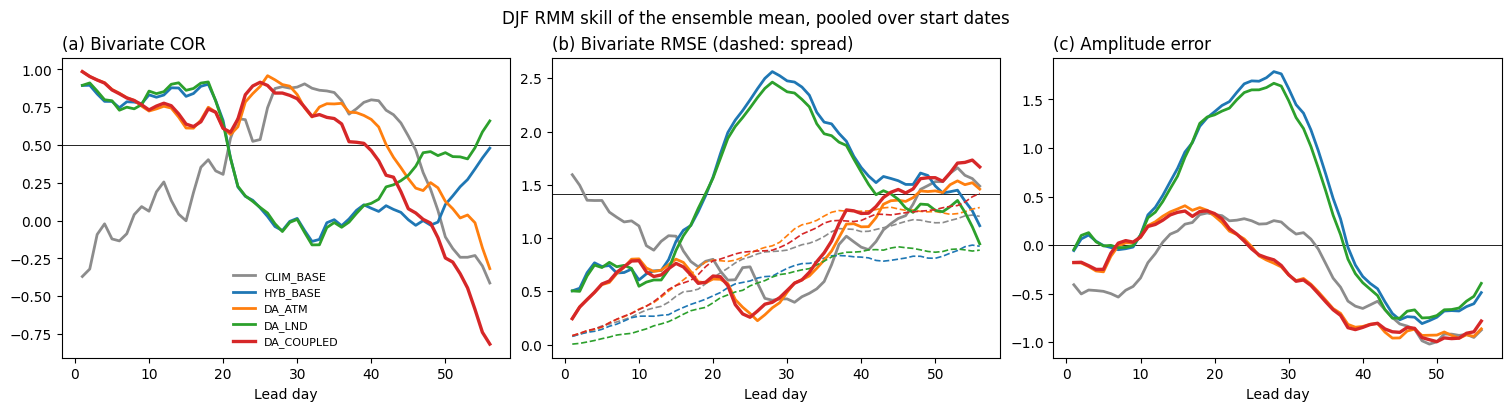

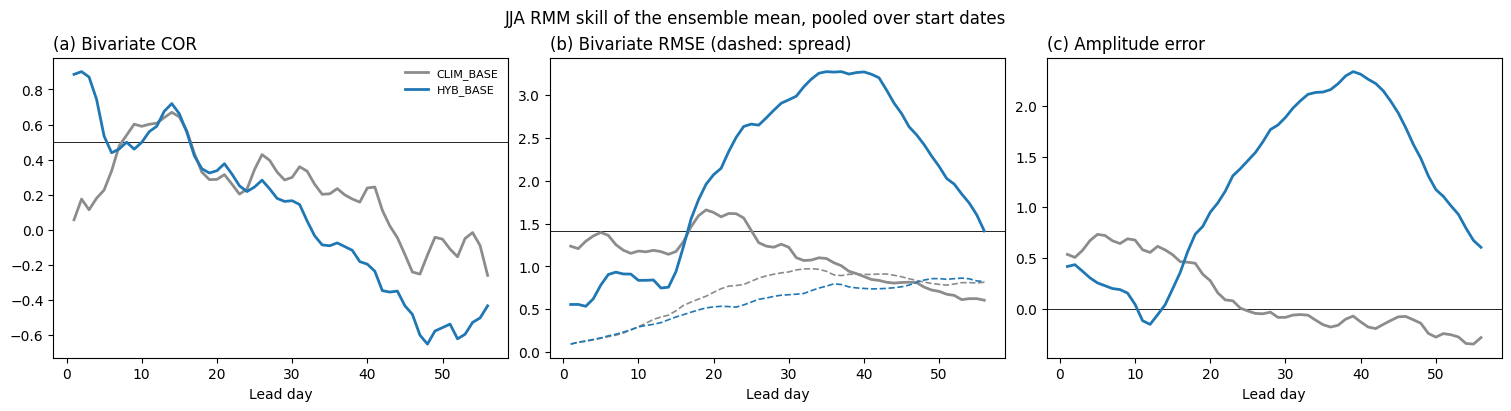

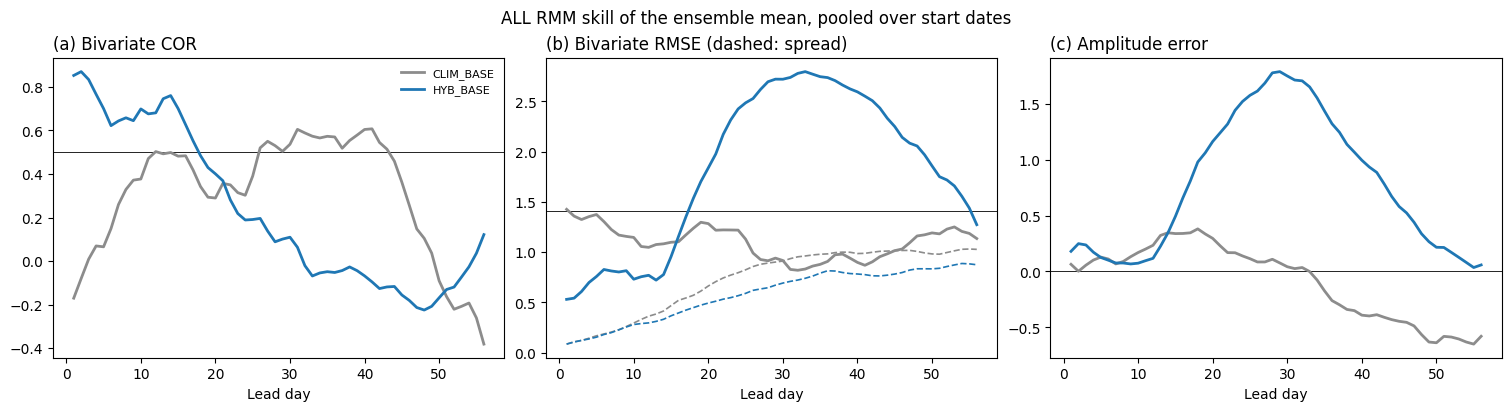

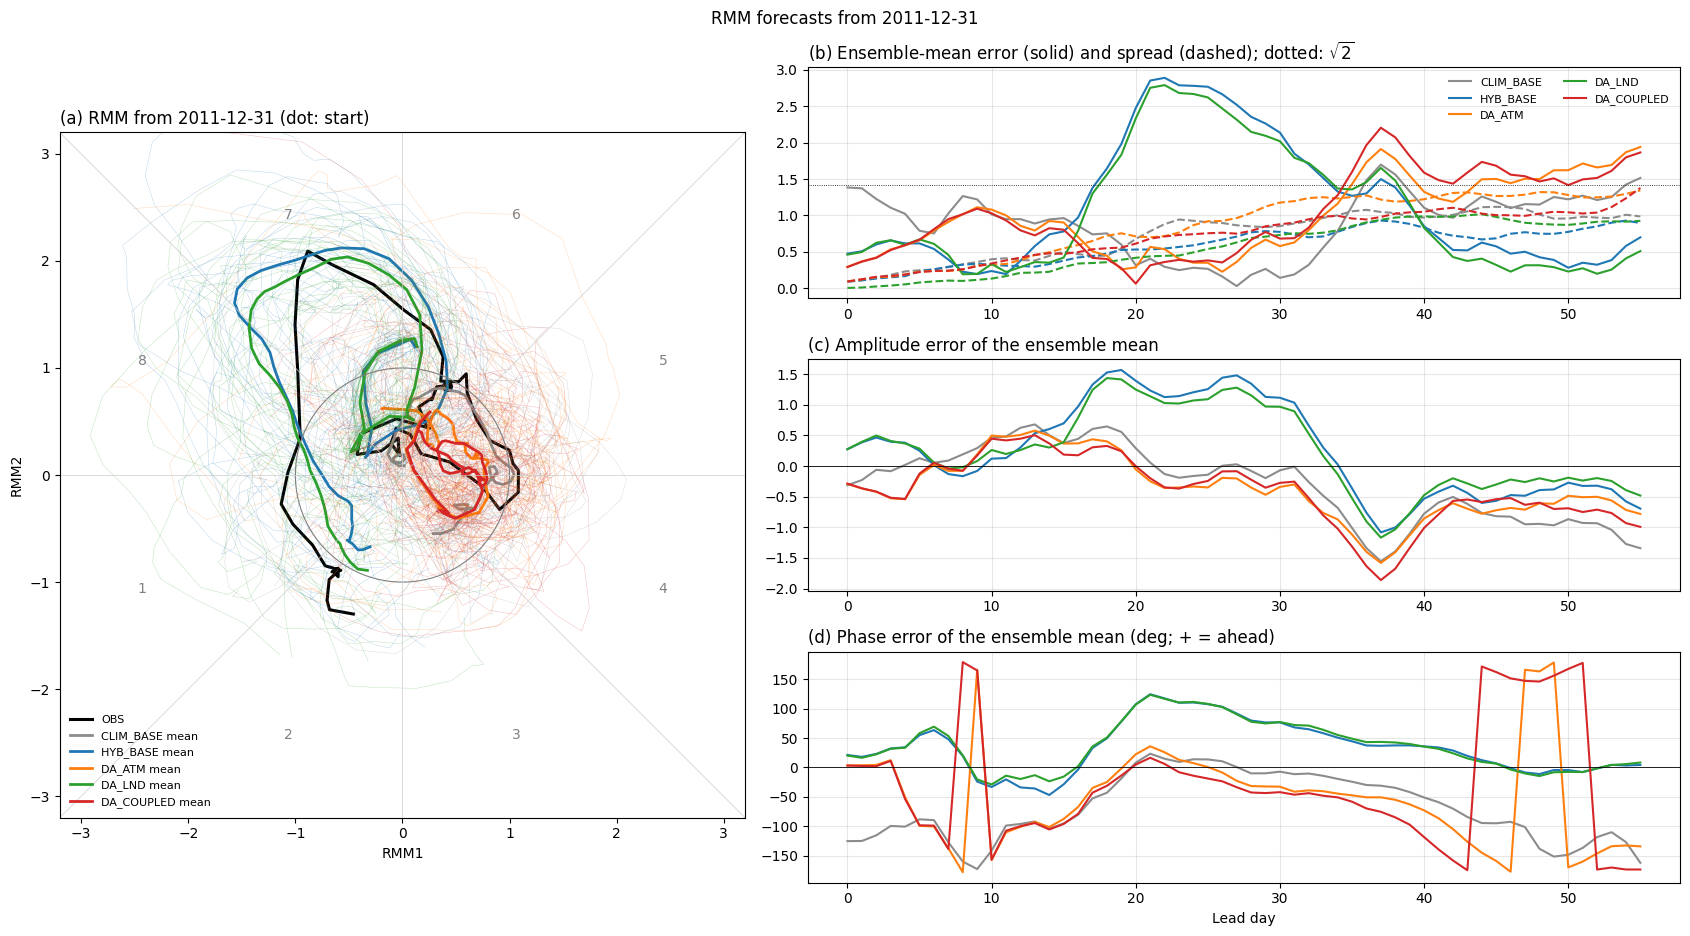

In [7]:
from configs.fcst_init_experiment_config import STYLE_MAP
from util.fcst_init_plotting import plot_rmm_scores
from util.mjo_rmm_projection import plot_ensemble_rmm

for name in sets:
    sub = {c: ds for (c, n), ds in lead_skill.items() if n == name}
    if sub:
        save(plot_rmm_scores(sub, max_lead=MAX_LEAD, season=name), f"rmm_lead_skill_{name}.png")
example = np.datetime64(EXAMPLE_INIT, "D")
ens = {c: fcst_rmm[c, example] for c in CONFIGS if (c, example) in fcst_rmm}
if ens:
    save(plot_ensemble_rmm(ens, obs_all, EXAMPLE_INIT, max_lead=MAX_LEAD,
                           colors={c: STYLE_MAP[c]["color"] for c in ens}, title=f"RMM forecasts from {EXAMPLE_INIT}"),
         f"rmm_ensemble_{EXAMPLE_INIT}.png")